# CNC Guard — 2. Fasea: Aurreprozesatzea eta Entrenamendua

**AABD Espezializazioa · 5071, 5072, 5073 moduluak**

Helburua: `ai4i2020_train.csv` datuetatik hutsegiteak iragarriko dituen eredu bat entrenatu eta `models/cnc_failure_model.pkl` gisa gorde.

## 1. Liburutegiak eta Karga

Beharrezko liburutegiak inportatu eta datuak kargatu.

In [22]:
# Liburutegiak inportatu
# ZURE KODEA HEMEN
from pathlib import Path
import sys

sys.path.insert(0, str(Path("../scoring").resolve()))  # cnc_ml inportatu ahal izateko

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (ConfusionMatrixDisplay,PrecisionRecallDisplay, classification_report,
                             confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, accuracy_score,precision_recall_curve,average_precision_score)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

from cnc_ml.columns import (FAILURE_SUBTYPES, MACHINE_TYPES, RAW_FEATURES, TARGET,
                            NUMERIC_FEATURES, ENGINEERED_FEATURES)
from cnc_ml.pipeline import build_pipeline
from app.services.model import FAILURE_THRESHOLD
import importlib
import app.services.model as m
importlib.reload(m)


<module 'app.services.model' from 'C:\\Users\\Admin\\Desktop\\T1-erronka1\\scoring\\app\\services\\model.py'>

In [3]:
# Datuak kargatu
df = pd.read_csv('../data/ai4i2020_train.csv')
# ZURE KODEA HEMEN

#-------SEGURTASUN ARNESA-----------
#df-an beharrezko zutabeak definitu
beharrezko_zutabeak = RAW_FEATURES + [TARGET]
# falta diren zutabeak inprimatu
falta_dira = set(beharrezko_zutabeak) - set(df.columns)
assert not falta_dira, f"Zutabe hauek falta dira CSV-an: {falta_dira}"

#hutsik ez dagoela begiratu / hutsk badago mesua inprimatua
assert len(df) > 0, "CSV-a hutsik dago"

#begiratu balore nuluak dauden edo ez
nuluak = df[beharrezko_zutabeak].isnull().sum() #zutabeka zenbatzen ditu
assert nuluak.sum() == 0, f"Balio nuluak daude:\n{nuluak[nuluak > 0]}"

#makina mota egokiak diren begiratu L,M,H
mota_ezezagunak = set(df["machine_type"]) - set(MACHINE_TYPES)
assert not mota_ezezagunak, f"machine_type ezezagunak: {mota_ezezagunak}"


assert set(df[TARGET].unique()) <= {0, 1}, f"{TARGET} 0 edo 1 izan behar da: {df[TARGET].unique()}"
assert df[TARGET].nunique() == 2, f"{TARGET}-ek bi klaseak behar ditu (0 eta 1)"

#Valore posibleak ezarri sentsore bakoitzantzako
barrutiak = {
    "air_temp_K": (250, 350),
    "process_temp_K": (250, 400),
    "rpm": (0, 5000),
    "torque_Nm": (0, 200),
    "tool_wear_min": (0, 500),
}
for zutabea, (bmin, bmax) in barrutiak.items():
    kanpoan = ~df[zutabea].between(bmin, bmax)
    assert not kanpoan.any(), f"{zutabea}: {kanpoan.sum()} balio [{bmin}, {bmax}] barrutitik kanpo"
print("Datuen balidazioa gaindituta")

Datuen balidazioa gaindituta


## 2. EDA — Datu-azterketa

Aztertu:
- Zutabe motak eta balioen barrutiak
- **Klase-banaketa**: zenbat hutsegite dute makinek? Zenbat dabiltza funtzionamendu egokian?
- Ezaugarrien arteko korrelazioa bilatu

> Galdera: klase-banaketa desorekatuak zein doiketa suposatzen d(it)u ereduan?

Dataset-a: 8000 errenkada eta 13 zutabe

machine_id             str
machine_type           str
air_temp_K         float64
process_temp_K     float64
rpm                  int64
torque_Nm          float64
tool_wear_min        int64
machine_failure      int64
failure_TWF          int64
failure_HDF          int64
failure_PWF          int64
failure_OSF          int64
failure_RNF          int64
dtype: object

--- Barrutiak ---
                   min         mean     max         std
air_temp_K       295.3   300.005450   304.5    1.996844
process_temp_K   305.7   310.006062   313.8    1.479432
rpm             1168.0  1539.356875  2886.0  180.982943
torque_Nm          3.8    40.003363    76.6   10.019546
tool_wear_min      0.0   107.685000   253.0   63.612002

Errenkada bikoiztuak: 0

--- Klase-banaketa ---
machine_failure
0    7729
1     271
Name: count, dtype: int64
machine_failure
0    96.61
1     3.39
Name: proportion, dtype: float64


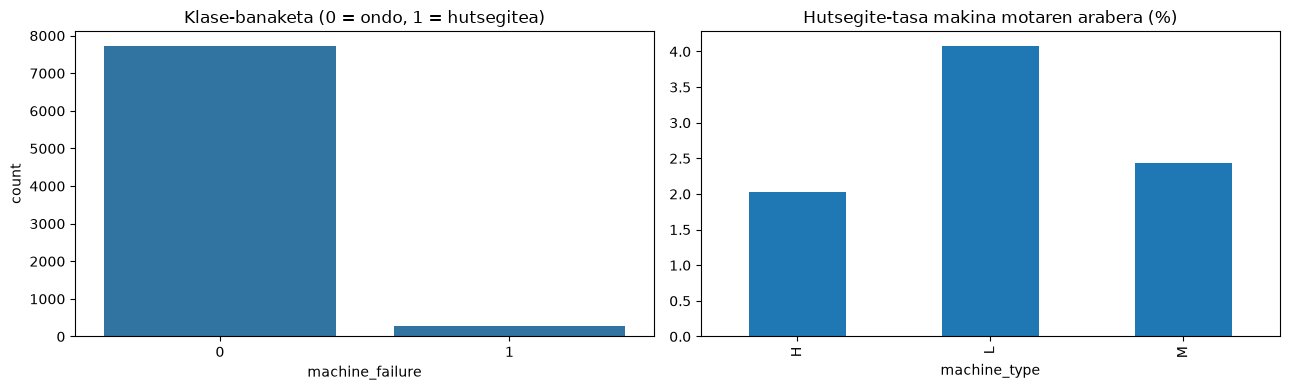

In [10]:
# EDA (1): egitura, barrutiak eta klase-banaketa
print(f"Dataset-a: {df.shape[0]} errenkada eta {df.shape[1]} zutabe\n")
print(df.dtypes)

# Balioen barrutiak
print("\n--- Barrutiak ---")
print(df[NUMERIC_FEATURES].describe().T[["min", "mean", "max", "std"]])

# Errenkada bikoiztuak (train-en eta val-en egonez gero data leakage sor dezakete)
print(f"\nErrenkada bikoiztuak: {df.duplicated().sum()}")

# Klase-banaketa
print("\n--- Klase-banaketa ---")
print(df[TARGET].value_counts())
print((df[TARGET].value_counts(normalize=True) * 100).round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(x=TARGET, data=df, ax=axes[0])
axes[0].set_title("Klase-banaketa (0 = ondo, 1 = hutsegitea)")
pd.crosstab(df["machine_type"], df[TARGET], normalize="index").mul(100)[1].plot.bar(ax=axes[1])
axes[1].set_title("Hutsegite-tasa makina motaren arabera (%)")
plt.tight_layout()
plt.show()

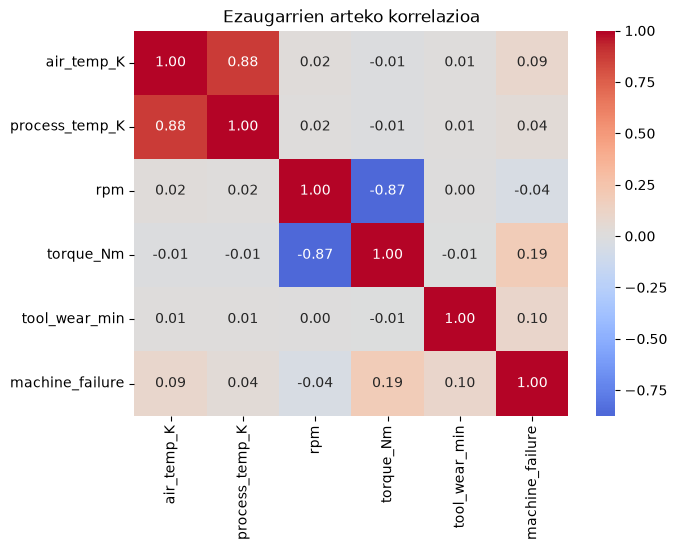

In [11]:
# EDA (2): korrelazioa
plt.figure(figsize=(7, 5))
sns.heatmap(df[NUMERIC_FEATURES + [TARGET]].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0)
plt.title("Ezaugarrien arteko korrelazioa")
plt.show()

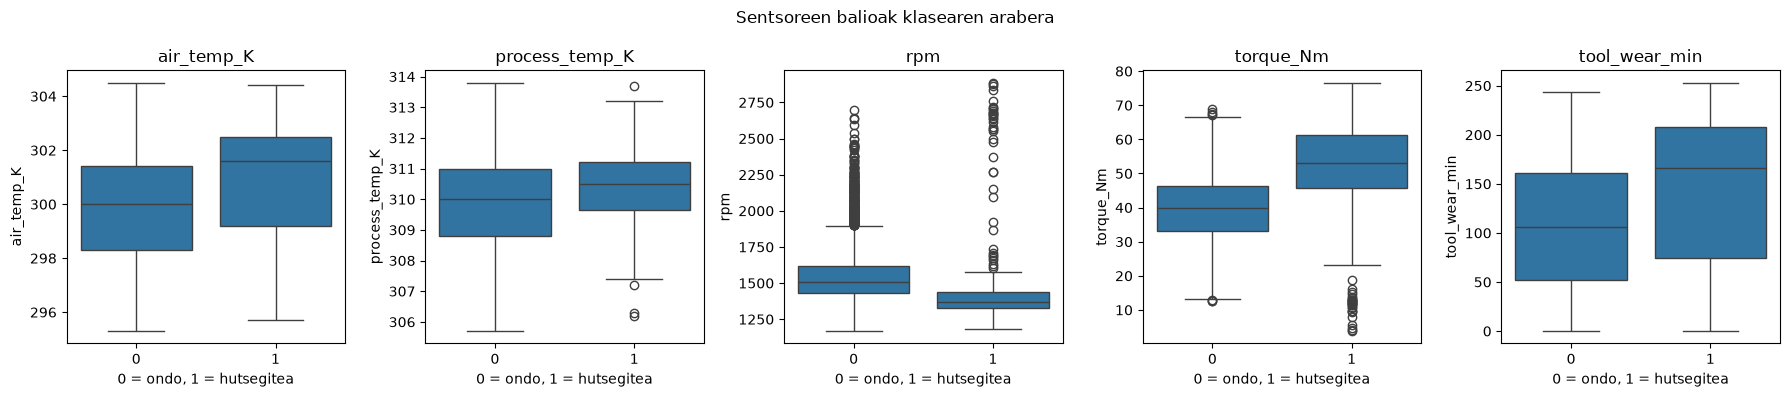

air_temp_K: outlier-ik ez
process_temp_K: outlier-ik ez
rpm: 331 outlier — horietatik %8.8 hutsegiteak dira
torque_Nm: 56 outlier — horietatik %89.3 hutsegiteak dira
tool_wear_min: outlier-ik ez


In [12]:
# EDA (3): outlier-ak — boxplot-ak klasearen arabera
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, zutabea in zip(axes, NUMERIC_FEATURES):
    sns.boxplot(x=TARGET, y=zutabea, data=df, ax=ax)
    ax.set_title(zutabea)
    ax.set_xlabel("0 = ondo, 1 = hutsegitea")
plt.suptitle("Sentsoreen balioak klasearen arabera")
plt.tight_layout()
plt.show()

# Outlier-ak (IQR metodoa) eta haien hutsegite-tasa
for zutabea in NUMERIC_FEATURES:
    q1, q3 = df[zutabea].quantile([0.25, 0.75])
    iqr = q3 - q1
    outlier = (df[zutabea] < q1 - 1.5 * iqr) | (df[zutabea] > q3 + 1.5 * iqr)
    if outlier.sum() > 0:
        tasa = df.loc[outlier, TARGET].mean() * 100
        print(f"{zutabea}: {outlier.sum()} outlier — horietatik %{tasa:.1f} hutsegiteak dira")
    else:
        print(f"{zutabea}: outlier-ik ez")

## EDA-ren ondorioak

**Klaseen banaketa:** 8.000 makinetatik 271k bakarrik izan dute hutsegitea (%3,4), hutsegite portzentaia oso baxua da. Hutsegite pixu baxua utxiko bagenuke ereduak beti "ez dago hutsegiteri egongo" esango luke. Hori ekiditzeko hurrengo pausoak emango ditugu: 
- Entrenatzean hutsegiteei pisu gehiago emango diegu (`class_weight="balanced"`).
- Atalasea 0,5etik behera jaitsiko dugu.
- Ez dugu accuracy begiratuko, recall eta F1 baizik.

**Korrelazioa:** Aire-tenperatura eta prozesu-tenperatura oso lotuta daude (0,88), eta rpm eta torkea ere bai, baina alderantziz (−0,87). Hutsegiteekin, aldiz, aldagai bakar batek ere ez du lotura handirik. Hau da, hutsegiteak ez dira aldagai bakar batengatik gertatzen, batzuen konbinazioagatik baizik. Horregatik aukeratu dugu Random Forest .

**Makina mota:** L motako makinek hutsegite gehiago dituzte (%4,1) M (%2,4) eta H (%2,0) motakoek baino.

**Outlier-ak:** Boxplot-etan ikusten da hutsegitea duten makinek torke handiagoa eta higadura handiagoa dutela. Torkearen 56 outlier-etatik %89 hutsegiteak dira, beraz ez ditugu kenduko: ez dira akatsak, guk aurkitu nahi ditugun kasuak baizik.

**Datuen kalitatea:** Ez dago balio hutsik ezta errenkada errepikaturik ere.

## 3. Aurreprozesatzea

Prestatu datuak entrenamendurako:
- Klase-desoreka tratatu (aukeratu ikuspegia eta **justifikatu**)
- (Aukerakoa) Feature engineering: ezaugarri artifizialak sortu,...

> Aukera posibleak?

In [13]:
# X eta y: X-k API-k bidaltzen dituen zutabeak bakarrik ditu (RAW_FEATURES)
X = df[RAW_FEATURES].copy()
y = df[TARGET].copy()

# ------- SEGURTASUN-ARNESA (2): data leakage -------
# X-k API-k bidaltzen dituen zutabe berberak izan behar ditu, ordena berean.
# Horrek bermatzen du failure_* (helburuaren azpimotak) eta machine_id ez daudela X-en.
assert list(X.columns) == RAW_FEATURES, f"X-ren zutabeak API-k bidaltzen dituenak izan behar dira: {RAW_FEATURES}"
print("Ez dago data leakage-rik X-en")
print(f"Aldagai iragarleak (X): {X.columns.tolist()}")



Ez dago data leakage-rik X-en
Aldagai iragarleak (X): ['machine_type', 'air_temp_K', 'process_temp_K', 'rpm', 'torque_Nm', 'tool_wear_min']


In [23]:
# Klase-desoreka: class_weight="balanced"-ek klase bakoitzari ematen dion pisua
# Formula: pisua = errenkada guztiak / (2 × klase horretako errenkadak)
# Hemen pisuak kalkulatu eta erakusten dira bakarrik; benetan 5. atalean aplikatzen dira.
pisuak = compute_class_weight("balanced", classes=np.array([0, 1]), y=y)
print(f"0 klasearen pisua (ondo):       {pisuak[0]:.2f}")
print(f"1 klasearen pisua (hutsegitea): {pisuak[1]:.2f}")
print(f"Hutsegite bakoitzak {pisuak[1] / pisuak[0]:.1f} aldiz pisu handiagoa du")

KLASE_PISUA = "balanced"   # 5. atalean ereduari pasatzen zaio

print(f"\n Aldagai iragarleak (X): {X.columns.tolist()}")
print(f"\nTarget-aren banaketa (y):\n{y.value_counts(normalize=True) * 100}%")

0 klasearen pisua (ondo):       0.52
1 klasearen pisua (hutsegitea): 14.76
Hutsegite bakoitzak 28.5 aldiz pisu handiagoa du

 Aldagai iragarleak (X): ['machine_type', 'air_temp_K', 'process_temp_K', 'rpm', 'torque_Nm', 'tool_wear_min']

Target-aren banaketa (y):
machine_failure
0    96.6125
1     3.3875
Name: proportion, dtype: float64%


### Klase-desoreka: zergatik `class_weight="balanced"`

Hiru aukera aztertu ditugu:
- **`class_weight="balanced"`**: ereduak hutsegite bakoitzari pisu handiagoa ematen dio . Ez du datu faltsurik sortzen eta ez du liburutegi gehigarririk behar.
- **SMOTE**: hutsegite sintetikoak sortzen ditu. Train-ean bakarrik aplikatu behar da (bestela data leakage) eta `imblearn`-en Pipeline berezia behar du, API-ra eramateko konplexuagoa.
- **Atalase-doiketa**: ez du eredua aldatzen, alarma noiz pizten den baizik.

**Erabakia:** `class_weight="balanced"` + atalase-doiketa (6b atala). Elkarren osagarri dira: lehenarekin ereduak hutsegiteak hobeto ikasten ditu, eta bigarrenarekin alarma kostuen arabera erabakitzen da.

## 4. Train / Validation Zatiketa

Garrantzitsua: `stratify=y` parametroa erabili klase-proportzioak mantentzeko.

In [7]:
# Train/val zatitu
# stratify=y: train eta validation multzoek hutsegiteen %3,4 bera mantentzen dute
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# SEGURTASUN-ARNESA (3): sentsore-balio berdinak dituen errenkadarik ez train-en eta val-en
# (balego, ereduak val-eko erantzuna "ikusita" izango luke → data leakage)
gainjarriak = pd.merge(X_train, X_val, how="inner").shape[0]
assert gainjarriak == 0, f"{gainjarriak} errenkada berdin daude train-en eta val-en"

print("Train / validation zatiketa zuzena")
print(f"Train:      {len(X_train)} errenkada ({y_train.sum()} hutsegite, %{y_train.mean()*100:.2f})")
print(f"Validation: {len(X_val)} errenkada ({y_val.sum()} hutsegite, %{y_val.mean()*100:.2f})")

Train / validation zatiketa zuzena
Train:      6400 errenkada (217 hutsegite, %3.39)
Validation: 1600 errenkada (54 hutsegite, %3.38)


## 5. Entrenamendua

Eredu bat (gutxienez) entrenatu. Aukerakoa: hainbat eredu konparatu.

In [ ]:
# Entrenamendua
# build_pipeline-ek 3 urrats lotzen ditu: feature engineering → aurreprozesatzea → eredua
pipeline = build_pipeline(
    RandomForestClassifier(
        n_estimators=100,          # 100 zuhaitz
        class_weight=KLASE_PISUA,  # klase-desoreka
        random_state=42,           # emaitza errepikagarria
    )
)

# fit: pipeline osoa train-ekin bakarrik entrenatzen da (scaler-a eta eredua)
pipeline.fit(X_train, y_train)
print("Eredua entrenatuta")


Eredua entrenatuta


### Zergatik Random Forest?

- **Erlazio ez-linealak** ikasten ditu: EDA-n ikusi dugu aldagai bakoitzak bere aldetik korrelazio ahula duela hutsegiteekin (altuena 0,19); hutsegiteak aldagaien konbinazioetatik datoz.
- **Outlier-ekiko sendoa** da eta ez du eskalatzerik behar.
- `class_weight` onartzen du klase-desoreka tratatzeko.
- `feature_importances_` ematen du, eta horrek eredua interpretatzen laguntzen du (G7).
- `predict_proba`-k probabilitateak ematen ditu, atalasea doitzeko beharrezkoak (6b atala).

## 6. Ebaluazioa

Ebaluatu honako metrikekin:
- `classification_report` — precision, **recall**, f1-score
- `confusion_matrix` — bistaratu eta interpretatu
- `roc_auc_score`

> Zergatik da recall garrantzitsuagoa precision baino kasu honetan?

--- Atalasea = 0.5 ---

                precision    recall  f1-score   support

      Ondo (0)      0.992     0.997     0.995      1546
Hutsegitea (1)      0.913     0.778     0.840        54

      accuracy                          0.990      1600
     macro avg      0.953     0.888     0.917      1600
  weighted avg      0.990     0.990     0.990      1600

ROC-AUC: 0.9740  (ez dago atalasearen menpe)

Nahasmen-matrizea:



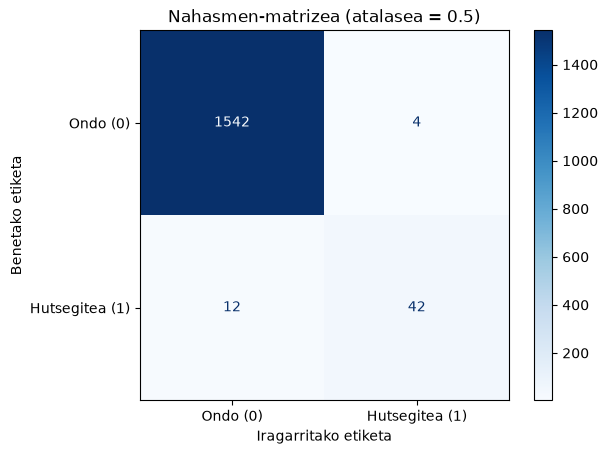

In [17]:
# Ebaluazioa
# Probabilitateak behin kalkulatzen dira eta 6., 6b eta 7. ataletan berrerabiltzen dira
y_proba = pipeline.predict_proba(X_val)[:, 1]

def ebaluatu(atalasea):
    """Metrikak eta nahasmen-matrizea atalase jakin batekin.
    Probabilitatea > atalasea bada, hutsegitea (1) iragartzen da."""
    y_pred = (y_proba > atalasea).astype(int)
    print(f"--- Atalasea = {atalasea} ---\n")
    print(classification_report(y_val, y_pred, digits=3,
                                target_names=["Ondo (0)", "Hutsegitea (1)"]))
    print(f"ROC-AUC: {roc_auc_score(y_val, y_proba):.4f}  (ez dago atalasearen menpe)")
    print(f"\nNahasmen-matrizea:\n")

    ConfusionMatrixDisplay.from_predictions(
        y_val, y_pred, display_labels=["Ondo (0)", "Hutsegitea (1)"], cmap="Blues")
    plt.title(f"Nahasmen-matrizea (atalasea = {atalasea})")
    plt.ylabel("Benetako etiketa")
    plt.xlabel("Iragarritako etiketa")
    plt.show()
    return y_pred

# Lehenik atalase lehenetsiarekin (0.5)
y_pred_05 = ebaluatu(0.5)

### Interpretazioa (atalasea 0,5)

| | Iragarria: ondo | Iragarria: hutsegitea |
|---|---|---|
| **Benetan ondo** | 1542 (TN) | 4 (FP) |
| **Benetan hutsegitea** | **12 (FN)** | 42 (TP) |

- 54 hutsegitetatik 42 detektatzen ditu, baina **12k ihes egiten dute (FN)**: recall = 0,78.
- Alarma faltsuak 4 baino ez dira: precision = 0,91.
- Accuracy-a %99 da, baina ez du ezer esaten: beti "0" esanez %96,6 lortuko litzateke.
- ROC-AUC = 0,974: ereduak oso ondo bereizten ditu bi klaseak; arazoa ez da eredua, **atalasea** baizik.

### Zergatik da recall garrantzitsuagoa precision baino?

- **FN** bat (hutsegitea ez detektatzea) = makina ustekabean gelditzea → ~**5.000 €**.
- **FP** bat (alarma faltsua) = mantentze-bisita bat → ~**200 €**.

FN bat FP bat baino 25 aldiz garestiagoa da. Beraz, nahiago dugu alarma faltsu batzuk izan hutsegite bat galdu baino. 0,5eko atalasearekin 12 FN ditugu → atalasea jaitsi behar da (6b atala).

Atalasea:      0.15
Zehaztasuna (accuracy):   0.9606
Doitasuna (precision):     0.4571
Estaldura (recall):     0.8889
F1 puntuazioa: 0.6038
ROC-AUC:       0.9740

--- Sailkapen-txostena (atalasea = 0.15) ---
              precision    recall  f1-score   support

           0       1.00      0.96      0.98      1546
           1       0.46      0.89      0.60        54

    accuracy                           0.96      1600
   macro avg       0.73      0.93      0.79      1600
weighted avg       0.98      0.96      0.97      1600



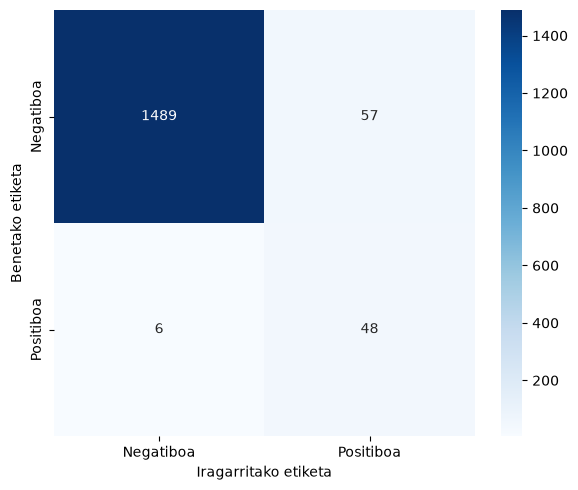

Umbral  | Falsos neg. | Falsos pos. | Recall | Precisión
----------------------------------------------------------
0.5     |          12 |           4 |   0.78 |      0.91
0.45    |          11 |           5 |   0.80 |      0.90
0.4     |          10 |           8 |   0.81 |      0.85
0.35    |          10 |          10 |   0.81 |      0.81
0.3     |          10 |          14 |   0.81 |      0.76
0.25    |          10 |          22 |   0.81 |      0.67
0.2     |           9 |          35 |   0.83 |      0.56
0.15    |           6 |          57 |   0.89 |      0.46
0.1     |           5 |          93 |   0.91 |      0.35


In [20]:
y_proba = pipeline.predict_proba(X_val)[:, 1]
y_pred = (y_proba > FAILURE_THRESHOLD).astype(int)

print(f"Atalasea:      {FAILURE_THRESHOLD}")
print(f"Zehaztasuna (accuracy):   {accuracy_score(y_val, y_pred):.4f}")  # accuracy
print(f"Doitasuna (precision):     {precision_score(y_val, y_pred):.4f}") # precision
print(f"Estaldura (recall):     {recall_score(y_val, y_pred):.4f}")    # recall
print(f"F1 puntuazioa: {f1_score(y_val, y_pred):.4f}")
print(f"ROC-AUC:       {roc_auc_score(y_val, y_proba):.4f}")

print(f"\n--- Sailkapen-txostena (atalasea = {FAILURE_THRESHOLD}) ---")
print(classification_report(y_val, y_pred))

#KONFUSION MATRIX

nahasket = confusion_matrix(y_val, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(nahasket, annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=["Negatiboa", "Positiboa"],
            yticklabels=["Negatiboa", "Positiboa"])
ax.set_ylabel("Benetako etiketa")
ax.set_xlabel("Iragarritako etiketa")
plt.tight_layout()
plt.show()
# ATALASE DESBERDINEKIN PROBA


print("Umbral  | Falsos neg. | Falsos pos. | Recall | Precisión")
print("-" * 58)
for umbral in [0.5, 0.45, 0.4, 0.35, 0.3, 0.25, 0.2, 0.15, 0.1]:
    pred = (y_proba > umbral).astype(int)
    fn = ((pred == 0) & (y_val == 1)).sum()
    fp = ((pred == 1) & (y_val == 0)).sum()
    rec = recall_score(y_val, pred)
    prec = precision_score(y_val, pred, zero_division=0)
    print(f"{umbral:<7} | {fn:>11} | {fp:>11} | {rec:>6.2f} | {prec:>9.2f}")

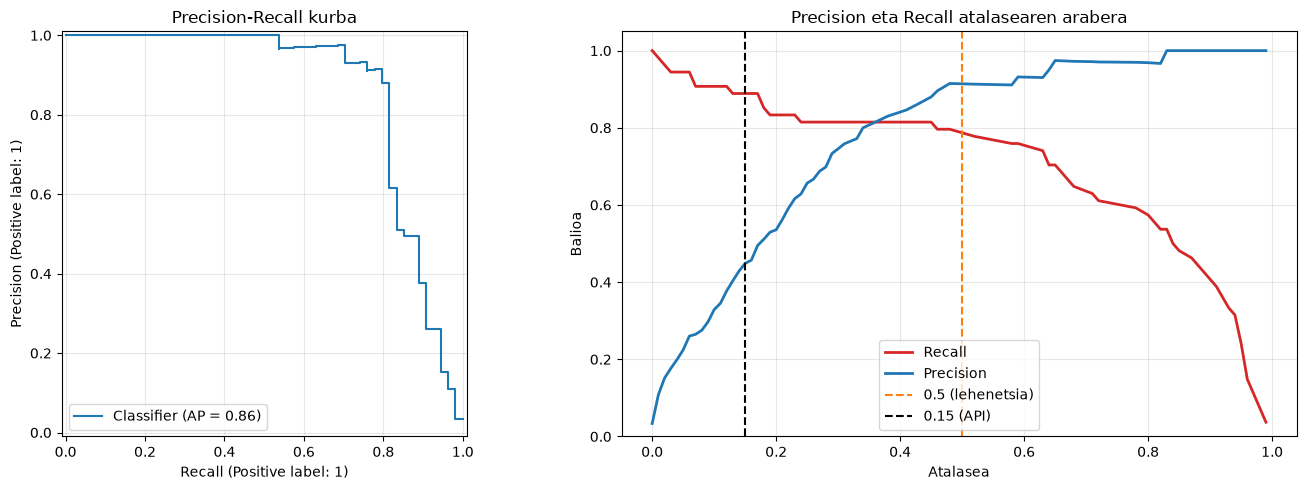

In [24]:
# 6b.2 — Precision-Recall kurba eta metrikak atalasearen arabera
precision, recall, atalaseak_pr = precision_recall_curve(y_val, y_proba)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. grafikoa: Precision-Recall kurba
PrecisionRecallDisplay.from_predictions(y_val, y_proba, ax=axes[0])
axes[0].set_title("Precision-Recall kurba")
axes[0].grid(alpha=0.3)

# 2. grafikoa: Precision eta Recall atalasearen arabera
axes[1].plot(atalaseak_pr, recall[:-1], lw=2, color="tab:red", label="Recall")
axes[1].plot(atalaseak_pr, precision[:-1], lw=2, color="tab:blue", label="Precision")
axes[1].axvline(0.5, color="tab:orange", ls="--", label="0.5 (lehenetsia)")
axes[1].axvline(FAILURE_THRESHOLD, color="black", ls="--", label=f"{FAILURE_THRESHOLD} (API)")
axes[1].set_xlabel("Atalasea")
axes[1].set_ylabel("Balioa")
axes[1].set_title("Precision eta Recall atalasearen arabera")
axes[1].set_ylim(0, 1.05)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Eredurik gabe (hutsegite guztiak FN):     270,000 €
Atalasea 0.5:                              73,400 €
Atalasea 0.15 (API):                       55,800 €


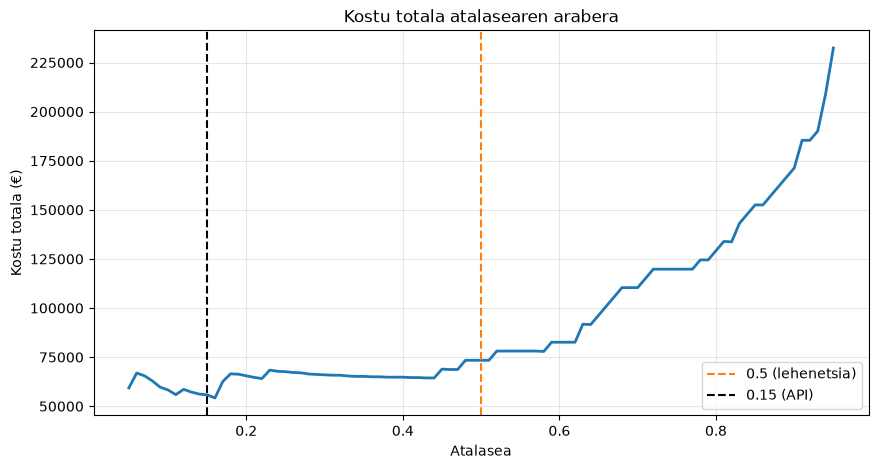

In [29]:
# 6b.3 — Kostu-analisia
# Kostu-taula ofiziala (€): FN = ustekabeko geldialdia, FP = alarma faltsua, TP = aurreikusitako konponketa
C_FN, C_FP, C_TP, C_TN = 5000, 200, 300, 0

atalaseak = np.round(np.arange(0.05, 0.96, 0.01), 2)
kostuak = []
for u in atalaseak:
    tn, fp, fn, tp = confusion_matrix(y_val, (y_proba > u).astype(int)).ravel()
    kostuak.append(C_FN * fn + C_FP * fp + C_TP * tp + C_TN * tn)


kostua_05 = kostuak[list(atalaseak).index(0.5)]
kostua_api = kostuak[list(atalaseak).index(FAILURE_THRESHOLD)]

print(f"{'Eredurik gabe (hutsegite guztiak FN):':<40}{C_FN * y_val.sum():>9,} €")
print(f"{'Atalasea 0.5:':<40}{kostua_05:>9,} €")
print(f"{f'Atalasea {FAILURE_THRESHOLD} (API):':<40}{kostua_api:>9,} €")


plt.figure(figsize=(10, 5))
plt.plot(atalaseak, kostuak, lw=2)
plt.axvline(0.5, color="tab:orange", ls="--", label="0.5 (lehenetsia)")
plt.axvline(FAILURE_THRESHOLD, color="black", ls="--", label=f"{FAILURE_THRESHOLD} (API)")
plt.xlabel("Atalasea")
plt.ylabel("Kostu totala (€)")
plt.title("Kostu totala atalasearen arabera")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 6b. Atalasearen Doikuntza (Threshold Tuning)

Atalase lehenetsiak (0.5) Negatibo Faltsu (FN) gehiegi uzten baditu, saiatu atalasea jaisten (adib. 0.20 edo 0.15):
- Erabili predict_proba probabilitateak lortzeko.
- Marraztu Precision-Recall kurba (PrecisionRecallDisplay) atalase optimoa aukeratzeko.
- Aplikatu atalase berria eta atera berriro classification_report eta confusion_matrix.

In [8]:
#0.5 atalsea erabiliz FN gehiegi uzten ziren, horregatik hasieratik (probak egin ostean) atalasea 0,2 ra jaitsi da
#atalasea model.py fitxategian dago definituta FAILURE_THRESHOLD balore globalean


# ATALASE DESBERDINEKIN PROBA


print("Umbral  | Falsos neg. | Falsos pos. | Recall | Precisión")
print("-" * 58)
for umbral in [0.5, 0.45, 0.4, 0.35, 0.3, 0.25, 0.2, 0.15, 0.1]:
    pred = (y_proba > umbral).astype(int)
    fn = ((pred == 0) & (y_val == 1)).sum()
    fp = ((pred == 1) & (y_val == 0)).sum()
    rec = recall_score(y_val, pred)
    prec = precision_score(y_val, pred, zero_division=0)
    print(f"{umbral:<7} | {fn:>11} | {fp:>11} | {rec:>6.2f} | {prec:>9.2f}")


Umbral  | Falsos neg. | Falsos pos. | Recall | Precisión
----------------------------------------------------------
0.5     |          12 |           4 |   0.78 |      0.91
0.45    |          11 |           5 |   0.80 |      0.90
0.4     |          10 |           8 |   0.81 |      0.85
0.35    |          10 |          10 |   0.81 |      0.81
0.3     |          10 |          14 |   0.81 |      0.76
0.25    |          10 |          22 |   0.81 |      0.67
0.2     |           9 |          35 |   0.83 |      0.56
0.15    |           6 |          57 |   0.89 |      0.46
0.1     |           5 |          93 |   0.91 |      0.35


## 7. Eredua Gorde

Scoring-api-k `/models/cnc_failure_model.pkl` bilatu behar du.

In [9]:
import joblib
# joblib.dump(model, '../models/cnc_failure_model.pkl')
# ZURE KODEA HEMEN

# Egiaztatu scoring-api-k ondo kargatzen duela:
# docker compose restart scoring-api
# curl http://localhost:8000/health  → 'model_loaded: true' ikusi behar da
import shutil
from datetime import datetime

from app.services.model import FAILURE_THRESHOLD, ModelService

# 1. Kalitate-kontrola: gutxieneko hauek gainditzen ez baditu, EZ da gordetzen
#    (API-k erabiltzen duen eredua ez hondatzeko). Atalasea API-rena bera da.
MIN_F1 = 0.60
MIN_RECALL = 0.85

y_proba = pipeline.predict_proba(X_val)[:, 1]
y_pred_api = (y_proba > FAILURE_THRESHOLD).astype(int)
f1 = f1_score(y_val, y_pred_api)
recall = recall_score(y_val, y_pred_api)
print(f"F1: {f1:.3f} (gutxienez {MIN_F1}) · Recall: {recall:.3f} (gutxienez {MIN_RECALL})")
assert f1 >= MIN_F1, f"F1 baxuegia ({f1:.3f} < {MIN_F1}): eredua EZ da gorde"
assert recall >= MIN_RECALL, f"Recall baxuegia ({recall:.3f} < {MIN_RECALL}): eredua EZ da gorde"

# 2. Eredu berria fitxategi tenporal batean gorde eta API-k bezala kargatu
ruta_modelo = Path("../models/cnc_failure_model.pkl")
ruta_tmp = ruta_modelo.with_suffix(".pkl.tmp")
joblib.dump(pipeline, ruta_tmp)
try:
    zerbitzua = ModelService()
    zerbitzua.load(str(ruta_tmp))
    assert zerbitzua.loaded, "Eredu berria ezin da kargatu"
    eskaera = X_val.iloc[0][RAW_FEATURES].to_dict()  # API-k jasotzen duen eskaera bezala
    prob = zerbitzua.predict_proba(eskaera)
    assert 0.0 <= prob <= 1.0, f"Probabilitate baliogabea: {prob}"
    assert abs(prob - pipeline.predict_proba(X_val.iloc[[0]])[0, 1]) < 1e-9, "Kargatutako ereduak ez du gauza bera iragartzen"
except Exception:
    ruta_tmp.unlink(missing_ok=True)  # eredu zaharra ukitu gabe geratzen da
    raise

# 3. Aurreko ereduaren babeskopia, eta gero ordezkatu
if ruta_modelo.exists():
    babeskopien_karpeta = ruta_modelo.parent / "backups"
    babeskopien_karpeta.mkdir(exist_ok=True)
    babeskopia = babeskopien_karpeta / f"cnc_failure_model_{datetime.now():%Y%m%d_%H%M%S}.pkl"
    shutil.copy2(ruta_modelo, babeskopia)
    print(f"Aurreko ereduaren babeskopia: {babeskopia}")
ruta_tmp.replace(ruta_modelo)
print(f"✔ Eredua gordeta eta egiaztatuta: {ruta_modelo}")

F1: 0.604 (gutxienez 0.6) · Recall: 0.889 (gutxienez 0.85)
Aurreko ereduaren babeskopia: ..\models\backups\cnc_failure_model_20261105_084339.pkl
✔ Eredua gordeta eta egiaztatuta: ..\models\cnc_failure_model.pkl
